La ley de Bendford es un tópico que por sí solo podría llenar este notebook, de fondo sus implicaciones son profundas, se ha convertido en una pieza fundamental en el análisis cotidiano en auditoría continua y en auditoría forense, para identificar posibles anomalías, inconsistencias o patrones inusuales que requieran revisión adicional   

<div style="text-align:left;">
    <a href="https://www.youtube.com/watch?v=uTcNHW1luH4" target="_blank">
        <img
            src="https://img.youtube.com/vi/uTcNHW1luH4/maxresdefault.jpg"
            alt="Análisis de datos"
            width="500"
        >
    </a>
    <p>haz clic en la imagen para abrir el vídeo, presenta una buena explicación</p>
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# creación de la función y su docstring (lo cual recomiendo, además de ser una buena práctica, queda claro para que sirve)

def benford_analysis(data, num_digits=1):
    """
    Realiza un análisis de Benford en los datos proporcionados considerando los primeros num_digits dígitos.

    Parameters:
        - data: Serie de datos a analizar.
        - num_digits: Número de dígitos a considerar (por defecto, 1).

    Returns:
        - result: Un DataFrame que muestra las frecuencias observadas y esperadas para cada dígito.
    """

    if num_digits <= 0:
        print("El número de dígitos debe ser mayor que cero.")
        return None

    # crear dataframe para almacenar los resultados
    result = pd.DataFrame(index=range(1, 10), columns=['Primer Dígito', 'Frecuencia Observada', 'Expectativa Benford'])

    # obtener los primeros num_digits dígitos de cada importe
    data_str = data.astype(str).str.replace(',', '')  # Eliminar comas de los números
    data_str = data_str.str.extract(r'(\d{' + str(num_digits) + r'})', expand=False)

    # calcular las frecuencias observadas
    digit_counts = data_str.value_counts().sort_index()
    for digit, count in digit_counts.items():
        result.at[int(digit), 'Primer Dígito'] = int(digit)
        result.at[int(digit), 'Frecuencia Observada'] = count

    # calcular las frecuencias esperadas según la Ley de Benford
    n = len(data)
    for digit in range(1, 10):
        result.at[digit, 'Expectativa Benford'] = np.log10(1 + 1 / digit) * n

    # rellenar NaN con ceros en el DataFrame result
    result = result.fillna(0)

    # visualizar los resultados en un gráfico de barras
    plt.figure(figsize=(8, 4))

    # gráfico de arras
    plt.bar(
        result['Primer Dígito'],
        result['Frecuencia Observada'],
        color='#4E79A7',
        edgecolor='white',
        linewidth=1,
        alpha=0.9,
        label='Frecuencia Observada'
    )

    # línea con los valores esperados de la Ley Benford
    plt.plot(
        result['Primer Dígito'],
        result['Expectativa Benford'],
        marker='o',
        markersize=6,
        linewidth=2.5,
        color='white',
        markerfacecolor='white',
        markeredgecolor='#4E79A7',
        label='Expectativa Benford'
    )

    # etiquetas de ejes
    plt.xlabel(
        f'Primeros {num_digits} Dígitos',
        fontsize=9
    )

    plt.ylabel(
        'Frecuencia',
        fontsize=9
    )

    # tamaño de los ejes
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)

    # título
    plt.title(
        f'Análisis de Benford ({num_digits} dígitos)',
        fontsize=13,
        fontweight='bold'
    )

    # cuadrícula
    plt.grid(
        axis='y',
        linestyle='--',
        alpha=0.3
    )

    # tamaño de leyenda 
    plt.legend(
        fontsize=8,
        frameon=False
    )

    plt.tight_layout()
    plt.show()

    # comprobar si la distribución observada se desvía significativamente de la esperada
    desviacion = sum(abs(result['Frecuencia Observada'] - result['Expectativa Benford']))
    if desviacion < 0.1:
        print("La distribución observada se ajusta bien a la Ley de Benford.")
    else:
        print("La distribución observada se desvía de la Ley de Benford. Puede requerir una revisión adicional.")

    return result

### Prueba con datos del archivo detalle ventas, que son apróximados a un escenario real

In [3]:
# importar datos e inspección inicial
datos = pd.read_excel(r'data\Detalle de ventas.xls')
datos.head()

,NUM_FACT,FECHA_FACT,VENDEDOR,NUM_CLI,COD_PROD,CANTIDAD,PRECIO_UNIT,BRUTO,IVA,NETO
0,1002646,2006-07-24,127,20954,3,100,36.62,3662.00,366.20,4028.20
1,1000750,2006-03-20,126,21164,4,499,112.39,52739.31,5273.93,58013.24
2,1001961,2006-06-13,107,40308,5,3549,7.03,24949.47,2494.95,27444.42
3,1000938,2006-06-02,102,40110,5,13,6.68,86.84,8.69,95.53
4,1001595,2006-03-21,123,20005,3,49,35.21,1725.29,172.53,1897.82


In [4]:
# consulta del nombre de las consultas
datos.columns

Index(['NUM_FACT', 'FECHA_FACT', 'VENDEDOR', 'NUM_CLI', 'COD_PROD', 'CANTIDAD',
       'PRECIO_UNIT', 'BRUTO', 'IVA', 'NETO'],
      dtype='str')

In [5]:
# inspección del tipo de datos
datos.dtypes

NUM_FACT                int64
FECHA_FACT     datetime64[us]
VENDEDOR                int64
NUM_CLI                 int64
COD_PROD                int64
CANTIDAD                int64
PRECIO_UNIT           float64
BRUTO                 float64
IVA                   float64
NETO                  float64
dtype: object

In [6]:
# exclusión de los importes iguales a cero en la serie objetivo: NETO
datos = datos.loc[datos.NETO != 0]

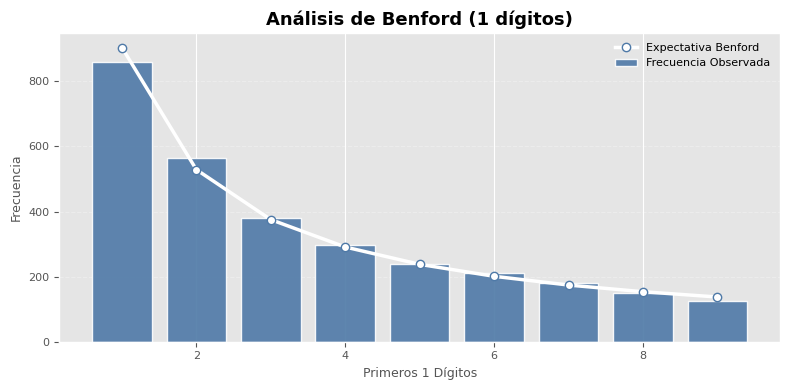

La distribución observada se desvía de la Ley de Benford. Puede requerir una revisión adicional.


,Primer Dígito,Frecuencia Observada,Expectativa Benford
1,1,858,903.69
2,2,563,528.63
3,3,379,375.07
4,4,296,290.92
5,5,239,237.7
6,6,212,200.97
7,7,180,174.09
8,8,150,153.56
9,9,125,137.36


In [7]:
benford_analysis(datos['NETO'], num_digits=1)

### Conclusión

Comparé los resultados obtenidos con este código y son exactamente iguales que los que se obtienen con ACL, solo habría que especificar el análisis con 2 o más dígitos significativos, por lo demás es bastante alcanzable descubrir posibles casos para investigar usando el análisis Benford, el cuál no es por sí solo un sinónimo de fraude, pero sí un buen indicador de que algo ha ocurrido al encontrar desviaciones contra las cifras esperadas por la Ley.